# JobGuard 02: Modelling
Stacked ensemble: NB + LR on text, RF + GB on metadata, combined by a meta Logistic Regression. Uses `../data/clean.pkl` from notebook 01.

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from features import build_features
sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
def save(name): plt.savefig(FIG + name, dpi=150, bbox_inches="tight"); plt.show()
import time, joblib
from sklearn.model_selection import train_test_split
from sklearn.metrics import (f1_score, precision_score, recall_score, average_precision_score, roc_auc_score,
    precision_recall_curve, classification_report, ConfusionMatrixDisplay, RocCurveDisplay, confusion_matrix)
from models import base_models, voting_model, stacking_model
df = pd.read_pickle("../data/clean.pkl")
y = df["fraudulent"]; X = df.drop(columns=["fraudulent"])
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.15/0.85, stratify=y_tmp, random_state=42)
print(len(X_train), len(X_val), len(X_test))

12319 2640 2640


## Train and compare on the validation set
The test set is untouched until the end. TF-IDF lives inside each Pipeline so it only learns from training data.

In [2]:
models = {**base_models(), "Voting (soft)": voting_model(), "Stacking": stacking_model()}
rows, fitted = [], {}
for name, m in models.items():
    t = time.time(); m.fit(X_train, y_train); dt = time.time() - t
    p = m.predict_proba(X_val)[:, 1]
    rows.append({"Model": name, "F1@0.5": f1_score(y_val, p >= .5), "Precision": precision_score(y_val, p >= .5, zero_division=0),
                 "Recall": recall_score(y_val, p >= .5), "PR-AUC": average_precision_score(y_val, p),
                 "ROC-AUC": roc_auc_score(y_val, p), "Train s": dt})
    fitted[name] = m
results = pd.DataFrame(rows).sort_values("PR-AUC", ascending=False).round(3).reset_index(drop=True)
results.to_csv("../reports/model_comparison.csv", index=False)
results

,Model,F1@0.5,Precision,Recall,PR-AUC,ROC-AUC,Train s
0,Stacking,0.718,0.568,0.977,0.951,0.996,168.938
1,Voting (soft),0.839,0.917,0.773,0.933,0.995,36.296
2,Random Forest,0.827,0.989,0.711,0.925,0.993,25.111
3,"kNN (text, cosine)",0.881,0.930,0.836,0.917,0.969,19.348
4,Logistic Regression,0.796,0.724,0.883,0.916,0.995,24.462
5,Gradient Boosting (meta),0.602,0.454,0.891,0.842,0.978,3.592
6,Naive Bayes (text),0.484,0.582,0.414,0.557,0.906,17.177
7,Decision Tree,0.622,0.483,0.875,0.491,0.918,34.012


PR-AUC is the headline metric for imbalanced data. Stacking's F1 at 0.5 is low only because 0.5 is the wrong threshold for it; we tune the threshold next.

chosen threshold: 0.976 | val F1: 0.885


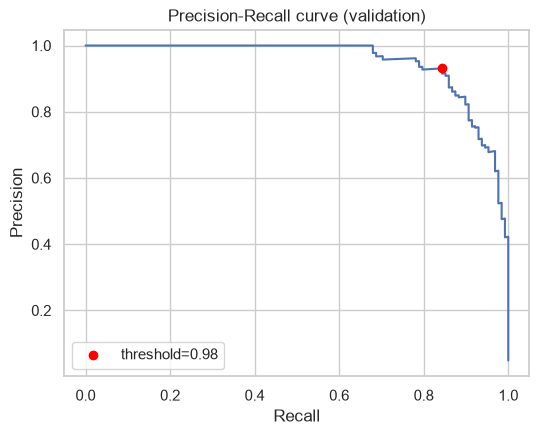

In [3]:
stack = fitted["Stacking"]
p_val = stack.predict_proba(X_val)[:, 1]
prec, rec, thr = precision_recall_curve(y_val, p_val)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
i = int(np.argmax(f1s[:-1])); threshold = float(thr[i])
print("chosen threshold:", round(threshold, 3), "| val F1:", round(f1s[i], 3))
plt.figure(figsize=(6,4.5)); plt.plot(rec, prec); plt.scatter(rec[i], prec[i], c="red", zorder=5, label=f"threshold={threshold:.2f}")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-Recall curve (validation)"); plt.legend()
save("09_pr_curve.png")

## Final test (touched once)

              precision    recall  f1-score   support

        Real       0.99      1.00      0.99      2512
        Fake       0.93      0.78      0.85       128

    accuracy                           0.99      2640
   macro avg       0.96      0.89      0.92      2640
weighted avg       0.99      0.99      0.99      2640

test PR-AUC: 0.936 | ROC-AUC: 0.995


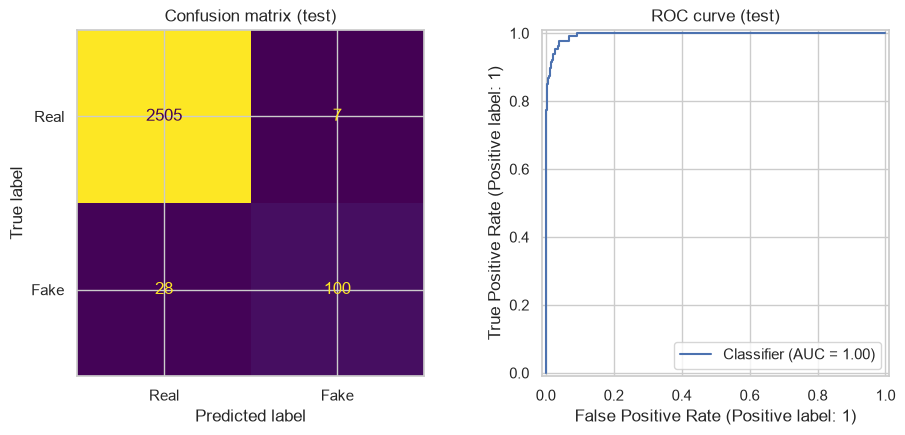

In [4]:
p_test = stack.predict_proba(X_test)[:, 1]
pred = (p_test >= threshold).astype(int)
print(classification_report(y_test, pred, target_names=["Real","Fake"]))
print("test PR-AUC:", round(average_precision_score(y_test, p_test), 3), "| ROC-AUC:", round(roc_auc_score(y_test, p_test), 3))
fig, axs = plt.subplots(1, 2, figsize=(11,4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Real","Fake"], ax=axs[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, p_test, ax=axs[1]); axs[0].set_title("Confusion matrix (test)"); axs[1].set_title("ROC curve (test)")
save("10_confusion_roc.png")

In [5]:
joblib.dump({"model": stack, "threshold": threshold}, "../models/jobguard.joblib", compress=3)
import os; print("saved", round(os.path.getsize("../models/jobguard.joblib")/1e6, 1), "MB")

saved 7.7 MB


## Explainability: top words from the Logistic Regression member

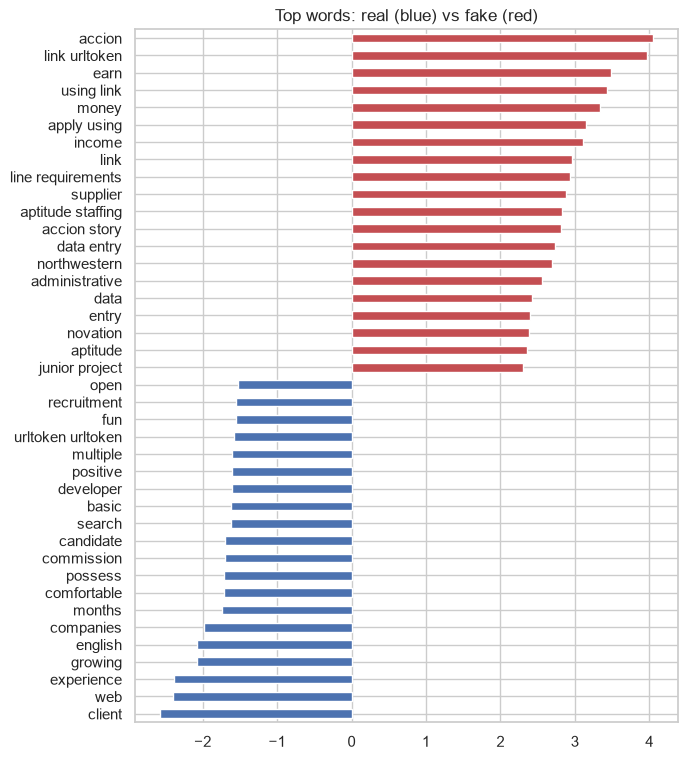

FAKE: ['accion', 'link urltoken', 'earn', 'using link', 'money', 'apply using', 'income', 'link', 'line requirements', 'supplier']
REAL: ['client', 'web', 'experience', 'growing', 'english', 'companies', 'months', 'comfortable', 'possess', 'commission']


In [6]:
lr = stack.named_estimators_["lr"]
vocab = lr.named_steps["f"].named_transformers_["tfidf"].get_feature_names_out()
coef = lr.named_steps["m"].coef_[0][:len(vocab)]
order = np.argsort(coef); top = np.r_[order[:20], order[-20:]]
s = pd.Series(coef[top], index=vocab[top]).sort_values()
plt.figure(figsize=(7,9)); s.plot.barh(color=["#4C72B0" if v < 0 else "#C44E52" for v in s]); plt.title("Top words: real (blue) vs fake (red)")
save("11_lr_top_words.png")
print("FAKE:", list(vocab[order[-10:]][::-1])); print("REAL:", list(vocab[order[:10]]))

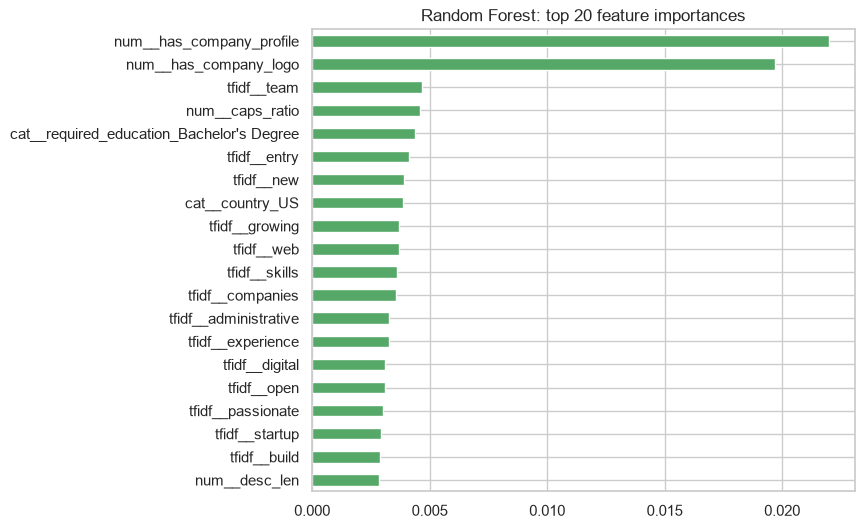

In [7]:
rf = stack.named_estimators_["rf"]
names = rf.named_steps["f"].get_feature_names_out()
imp = pd.Series(rf.named_steps["m"].feature_importances_, index=names).sort_values().tail(20)
plt.figure(figsize=(7,6)); imp.plot.barh(color="#55A868"); plt.title("Random Forest: top 20 feature importances")
save("12_rf_importance.png")

## Bias check: US vs non-US
The training data is mostly American ads from 2012-2014, so the model may miss more scams elsewhere.

In [8]:
res = X_test.assign(y=y_test.values, pred=pred)
res["region"] = np.where(res["country"] == "US", "US", "Non-US")
for g, d in res.groupby("region"):
    tn, fp, fn, tp = confusion_matrix(d.y, d.pred, labels=[0, 1]).ravel()
    print(g, "n =", len(d), "| recall:", round(tp / max(tp + fn, 1), 3), "| FPR:", round(fp / max(fp + tn, 1), 3))

Non-US n = 1066 | recall: 0.722 | FPR: 0.001
US n = 1574 | recall: 0.791 | FPR: 0.004


## Leakage audit
- Duplicates removed before splitting.
- TF-IDF inside the Pipeline (fit on train only).
- Test set used once.
- Scammers repost near-copies of the same ad, which can inflate scores (notably kNN, which finds near-copies). A grouped split by `description` would likely lower the scores.

## Limitations
Old, mostly-US data. Treat the score as a warning, not proof.